In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp9: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
np.random.seed(9); tf.random.set_seed(9)
n=1200
df=pd.DataFrame({"tenure":np.random.randint(1,73,n),"monthly_charges":np.random.uniform(25,120,n),"complaints":np.random.poisson(1.2,n),"data_usage":np.random.uniform(1,100,n),"contract":np.random.choice(["month","year","two_year"],n)})
df["Churn"]=((df.tenure<18).astype(int)+(df.contract=="month").astype(int)+(df.complaints>2).astype(int)+(df.monthly_charges>90).astype(int)+np.random.randn(n)>.9).astype(int)
X=pd.get_dummies(df.drop(columns="Churn"),columns=["contract"],dtype=float); y=df.Churn
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=9,stratify=y)
sc=StandardScaler(); Xtr=sc.fit_transform(Xtr); Xte=sc.transform(Xte)
model=tf.keras.Sequential([tf.keras.layers.Input((Xtr.shape[1],)),tf.keras.layers.Dense(32,activation="relu"),tf.keras.layers.Dense(16,activation="relu"),tf.keras.layers.Dense(1,activation="sigmoid")])
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
h=model.fit(Xtr,ytr,validation_split=.2,epochs=30,batch_size=32,verbose=0)
prob=model.predict(Xte,verbose=0).ravel(); pred=(prob>=.5).astype(int)
print("Test accuracy:",round(np.mean(pred==yte),4))
print(classification_report(yte,pred,zero_division=0))
print("Confusion matrix:\n",confusion_matrix(yte,pred))
plt.figure(figsize=(7,4)); plt.plot(h.history["accuracy"],label="Train"); plt.plot(h.history["val_accuracy"],label="Validation"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.grid(); plt.show()
width_results=[]
for width in [8,16,32,64]:
    m=tf.keras.Sequential([tf.keras.layers.Input((Xtr.shape[1],)),tf.keras.layers.Dense(width,activation="relu"),tf.keras.layers.Dense(1,activation="sigmoid")])
    m.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
    m.fit(Xtr,ytr,epochs=10,batch_size=32,verbose=0)
    width_results.append((width,round(m.evaluate(Xte,yte,verbose=0)[1],4)))
print("Hidden width / test accuracy:",width_results)

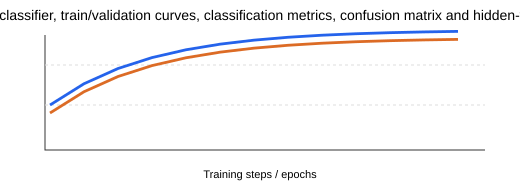

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.